# Stage 3: TIL regions

Four regions with a high local density of T cells (TILs), one per sample. Each region is cropped from the raw Xenium output and given its own QC and normalisation, then cells are re-labelled by gene-set scoring within the region. These region-level labels are used for TIL composition and the immune marker dot plot.

The steps follow the original notebooks for each region and the original TIL plotting notebook. PCA, UMAP and Leiden clustering are left out, because the labels don't depend on them.

## Parameters

In [1]:
import os

# Raw Xenium output, one subfolder per sample (cell_feature_matrix.h5 and cells.csv)
RAW_DATA_DIR = "/path/to/raw_xenium"
RAW_DIRS = {
    "MH065_480": f"{RAW_DATA_DIR}/MH065_480",
    "MH106_480": f"{RAW_DATA_DIR}/MH106_480",
    "MH107_480": f"{RAW_DATA_DIR}/MH107_480",
    "MH106_314": f"{RAW_DATA_DIR}/MH106_314",
}
# Malignant-cell regions from stage3_malignant_TIL.ipynb, for the distances to immune cells
MALIGNANT_DIR = "/path/to/stage3_output/malignant_TIL"
OUTPUT_DIR = "/path/to/stage3_output/TIL_regions"
FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")
# The original region objects, used only for the check at the end; set to None to skip it
ARCHIVED_DIR = "/path/to/original_regions"
archived_files = {
    "MH065_480": "MH065_480_ss_cropped_immune#1.h5ad",
    "MH107_480": "MH107_480_ss_cropped_immune#1.h5ad",
    "MH106_480": "MH106_480_ss_cropped_immune#1.h5ad",
    "MH106_314": "Fig5_0010617_Region3_Immune_ss_Jun25.h5ad",
}

# Region as (x_min, x_max, y_min, y_max) in µm, minimum counts per cell, and the score quantile for labelling
til_regions = {
    "MH065_480": {"box": (8500, 10000, 1800, 3600), "min_counts": 8, "quantile": 0.75},
    "MH107_480": {"box": (8000, 10000, 280, 3200), "min_counts": 10, "quantile": 0.75},
    "MH106_480": {"box": (5200, 6400, 1800, 3600), "min_counts": 8, "quantile": 0.75},
    "MH106_314": {"box": (1500, 4500, 3000, 5500), "min_counts": 15, "quantile": 0.70},
}

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import squidpy as sq
from scipy.spatial import cKDTree

os.makedirs(FIGURE_DIR, exist_ok=True)
sc.settings.figdir = FIGURE_DIR

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


## Gene sets for labelling, from each region's original notebook

In [3]:
gene_sets_by_sample = {}

gene_sets_by_sample["MH065_480"] = {
    'Malignant cells': ['KRT8','KRT19','KRT7','KRT17'],
    #'IPMN': {'MUC2','REG4','SPINK4'}, 
    #'Ductal MUC5B': {'MUC5B','REG1A','CSF1R','SLC4A4'},
    #'Ductal' : {'CFTR','SLC4A4','PKHD1','CRP'},
    #'Acinar' : {'CTRC','CUZD1','PRSS1','AMY2A'},
    #'Acinar_REG+' : {'REG1B','REG3G','REG3A'},
    #'Malignant acinar' : {'MUCL3','NPSR1','PCDH7','REG1B','PRSS1'},
    #'Tuft' : {'AVIL','TRPM5','BMX'},
    #'Endocrine': ['PPY','INS','GCG'],
    # TLS  - this is outside TLS regions
    #'FDCs': ['VCAM1','FDCSP','CR2','CCL19'],
    #'FRCs': ['PLA2G2A','IGF1','IL1R1','PDPN','PDGFRA','MEDAG'], 
    #'Stromal_CCL19' : ['PDGFRA','CCL19','VCAM1'], #,'CXCL12',
    #'HEV': ['MEOX2'], #,'CHST4','ANKRD53'
    #'LECs': ['LYVE1','FLT4','PROX1'], 
    # Stromal
    'Endothelial' : ['VWF','PLVAP','FLT1','KDR'],
    #'SMCs' : ['MYH11','PDGFRB'], #don't use ACTA2
    'Pericytes': ['PDGFRB','RGS5'],
    #'Schwann': ['SOX10','CDH19','CHL1','NGFR'],
    #'Neurons': ['SYT1','CNTNAP2'],
    'Adipocytes': ['ADIPOQ','PLIN1','LIPE'],
    # CAFs
    'CAFs_MYO': ['POSTN','MMP11','COL11A1'],
    #'CAFs_CXCL14': ['COL11A1','CXCL14','POSTN'], # Not many CXCL14, mostly CAFs-MYO
    'CAFs_NRT' : ['PDGFRA','SCN7A','C7','ABCA6','ABCA10','KCNIP1','ABCA8','CXCL12'],
    # Lymphoid
    'NK': ['GNLY', 'NKG7','KLRC1'], #very few
    'CD4 T cells': ['IL7R','CD4','TCF7'],
    'CD4 Treg' : ['FOXP3','IKZF2','CCR8'],
    'CD4 Tfh' : ['CD4','ICOS','PDCD1'], 
    'CD8 T cells': ['CD8A','CD8B','GZMK','KLRG1'],
    'CD8 TRM' : ['CD8A','CD8B','ITGAE','CD226','CXCR6','ID2'],
    #'B cells': ['MS4A1','CD19','FCRL1'], - this is outside TLS regions
    #'B:GC' : {'LMO2','BCL6','CD22','MS4A1'},- this is outside TLS regions
    'Plasma': ['MZB1','JCHAIN'],
    'gdT' : ['XCL1','TRGC1','TRGC2'],
    # Myeloid
    'Neutrophils': ['CSF3R','FCGR3B','TREM1'],
    'DC1' : ['CLEC9A','IDO1'],
    'DC2' : ['CLEC10A','CD1C'],
    'pDCs' :['LILRA4','IL3RA'],
    #'Langerhans DCs' : {'CDH20','CD207','CD1A'},
    'Migratory DCs' : ['CCL22','LAMP3'],
    'Mast' : ['CPA3','KIT','TPSAB1'], 
    'TAMs_SPP1' : ['LIPA','SPP1','MARCO','CHIT1'], #CSTB/SLA2A1 EXPRESSED BY MALIGNANT CELLS# 'SPP1' expressed by endothelial, ductal and TAMs, not present
    'TAMs_OLR1' : ['OLR1','HBEGF'],
    'TAMs_C1QC' : ['C1QC','SELENOP','C1QA','F13A1','SLC40A1'],
    'TAMs_MHC' : ['CD86','IL1R2','HLA-DRB1','HLA-DRB5','CSF1R']
}

gene_sets_by_sample["MH106_480"] = {
    'Malignant cells': ['KRT8','KRT19','KRT7','KRT17'],
    #'IPMN': {'MUC2','REG4','SPINK4'}, 
    #'Ductal MUC5B': {'MUC6','TFF2','TFF3','FCGBP','CSF1R','SLC4A4'},
    #'Ductal' : {'CFTR','SLC4A4','PKHD1','CRP'},
    #'Acinar' : {'CTRC','CUZD1','PRSS1','AMY2A'},
    #'Acinar_REG+' : {'REG1B','REG3G','REG3A'},
    #'Malignant acinar' : {'MUCL3','NPSR1','PCDH7','REG1B','PRSS1'},
    #'Tuft' : {'AVIL','TRPM5','BMX'},
    'Endocrine': ['PPY','INS','GCG'],
    # TLS 
    #'FDCs': ['VCAM1','FDCSP','CR2','CCL19'],
    #'FRCs': ['PLA2G2A','IL1R1','PDPN','PDGFRA','MEDAG'], 
    #'Stromal_CCL19' : ['PDGFRA','CCL19','VCAM1'], #,'CXCL12',
    #'HEV': ['MEOX2'], #,'CHST4','ANKRD53'
    'LECs': ['LYVE1','FLT4','PROX1'], 
    # Stromal
    'Endothelial' : ['VWF','PLVAP','FLT1','KDR'],
    #'SMCs' : ['MYH11','PDGFRB'], #don't use ACTA2
    'Pericytes': ['PDGFRB','RGS5'],
    #'Schwann': ['SOX10','CDH19','CHL1','NGFR'],
    #'Neurons': ['SYT1','CNTNAP2'],
    #'Adipocytes': ['ADIPOQ','PLIN1','LIPE'],
    # CAFs
    'CAFs_MYO': ['POSTN','MMP11','COL11A1'],
    'CAFs_CXCL14': ['COL11A1','CXCL14','POSTN'], # Not many CXCL14, mostly CAFs-MYO
    'CAFs_NRT' : ['PDGFRA','SCN7A','C7','ABCA6','ABCA10','KCNIP1','ABCA8','CXCL12'],
    # Lymphoid
    'NK': ['GNLY', 'NKG7','KLRC1'], #very few
    'CD4 T cells': ['IL7R','CD4','TCF7'],
    'CD4 Treg' : ['FOXP3','IKZF2','CCR8'],
    #'CD4 Tfh' : ['CD4','ICOS','PDCD1'], 
    'CD8 T cells': ['CD8A','CD8B','GZMK','KLRG1'],
    'CD8 TRM' : ['CD8A','CD8B','ITGAE','CD226','CXCR6','ID2'],
    #'B cells': ['MS4A1','CD19','FCRL1'],
    #'B:GC' : {'LMO2','BCL6','CD22','MS4A1'},
    'Plasma': ['MZB1','JCHAIN'],
    'gdT' : ['XCL1','TRGC1','TRGC2'],
    # Myeloid
    #'Neutrophils': ['CSF3R','FCGR3B','TREM1'],
    'DC1' : ['CLEC9A','IDO1'],
    'DC2' : ['CLEC10A','CD1C'],
    'pDCs' :['LILRA4','IL3RA'],
    #'Langerhans DCs' : {'CDH20','CD207','CD1A'},
    'Migratory DCs' : ['CCL22','LAMP3'],
    'Mast' : ['CPA3','KIT','TPSAB1'], 
    'TAMs_SPP1' : ['LIPA','SPP1','MARCO','CHIT1'], #CSTB/SLA2A1 EXPRESSED BY MALIGNANT CELLS# 'SPP1' expressed by endothelial, ductal and TAMs, not present
    'TAMs_OLR1' : ['OLR1','HBEGF'],
    'TAMs_C1QC' : ['C1QC','SELENOP','C1QA','F13A1','SLC40A1'],
    'TAMs_MHC' : ['CD86','IL1R2','HLA-DRB1','HLA-DRB5','CSF1R']
}

gene_sets_by_sample["MH107_480"] = {
    'Malignant cells': ['KRT8','KRT19','KRT7','KRT17'],
    #'IPMN': {'MUC2','REG4','SPINK4'}, 
    #'Ductal MUC5B': {'MUC6','TFF2','TFF3','FCGBP','CSF1R','SLC4A4'},
    #'Ductal' : {'CFTR','SLC4A4','PKHD1','CRP'},
    #'Acinar' : {'CTRC','CUZD1','PRSS1','AMY2A'},
    #'Acinar_REG+' : {'REG1B','REG3G','REG3A'},
    #'Malignant acinar' : {'MUCL3','NPSR1','PCDH7','REG1B','PRSS1'},
    #'Tuft' : {'AVIL','TRPM5','BMX'},
    #'Endocrine': ['PPY','INS','GCG'],
    # TLS 
    #'FDCs': ['VCAM1','FDCSP','CR2','CCL19'],
    'FRCs': ['PLA2G2A','IGF1','IL1R1','PDPN','PDGFRA','MEDAG'], 
    'Stromal_CCL19' : ['PDGFRA','CCL19','VCAM1'], #,'CXCL12',
    #'HEV': ['MEOX2'], #,'CHST4','ANKRD53'
    'LECs': ['LYVE1','FLT4','PROX1'], 
    # Stromal
    'Endothelial' : ['VWF','PLVAP','FLT1','KDR'],
    'SMCs' : ['MYH11','PDGFRB'], #don't use ACTA2
    'Pericytes': ['PDGFRB','RGS5'],
    'Schwann': ['SOX10','CDH19','CHL1','NGFR'],
    #'Neurons': ['SYT1','CNTNAP2'],
    'Adipocytes': ['ADIPOQ','PLIN1','LIPE'],
    # CAFs
    'CAFs_MYO': ['POSTN','MMP11','COL11A1'],
    'CAFs_CXCL14': ['COL11A1','CXCL14','POSTN'], # Not many CXCL14, mostly CAFs-MYO
    'CAFs_NRT' : ['PDGFRA','SCN7A','C7','ABCA6','ABCA10','KCNIP1','ABCA8','CXCL12'],
    # Lymphoid
    'NK': ['GNLY', 'NKG7','KLRC1'], #very few
    'CD4 T cells': ['IL7R','CD4','TCF7'],
    'CD4 Treg' : ['FOXP3','IKZF2','CCR8'],
    'CD4 Tfh' : ['CD4','ICOS','PDCD1'], 
    'CD8 T cells': ['CD8A','CD8B','GZMK','KLRG1'],
    'CD8 TRM' : ['CD8A','CD8B','ITGAE','CD226','CXCR6','ID2'],
    #'B cells': ['MS4A1','CD19','FCRL1'],
    #'B:GC' : {'LMO2','BCL6','CD22','MS4A1'},
    'Plasma': ['MZB1','JCHAIN'],
    'gdT' : ['XCL1','TRGC1','TRGC2'],
    # Myeloid
    'Neutrophils': ['CSF3R','FCGR3B','TREM1'],
    'DC1' : ['CLEC9A','IDO1'],
    'DC2' : ['CLEC10A','CD1C'],
    'pDCs' :['LILRA4','IL3RA'],
    #'Langerhans DCs' : {'CDH20','CD207','CD1A'},
    'Migratory DCs' : ['CCL22','LAMP3'],
    'Mast' : ['CPA3','KIT','TPSAB1'], 
    'TAMs_SPP1' : ['LIPA','SPP1','MARCO','CHIT1'], #CSTB/SLA2A1 EXPRESSED BY MALIGNANT CELLS# 'SPP1' expressed by endothelial, ductal and TAMs, not present
    'TAMs_OLR1' : ['OLR1','HBEGF'],
    'TAMs_C1QC' : ['C1QC','SELENOP','C1QA','F13A1','SLC40A1'],
    'TAMs_MHC' : ['CD86','IL1R2','HLA-DRB1','HLA-DRB5','CSF1R']
}

gene_sets_by_sample["MH106_314"] = {
    'Malignant cells': ['KRT7','KRT8','KRT19','ACTN4'],
    #'IPMN': {'MUC2','REG4','SPINK4'}, 
    #'Ductal MUC5B': {'MUC6','MUC5B','FCGBP','SLC4A4'},
    'Ductal' : {'CFTR','SLC4A4'},
    #'Ductal MUC6': ['MUC6','REG1A','CFTR','SLC4A4'],
    #'Acinar' : {'CTRC','CUZD1','PRSS1','AMY2A'},
    #'Acinar_REG+' : {'REG1B','REG3G','REG3A'},
    #'Malignant acinar' : {'MUCL3','NPSR1','PCDH7','REG1B','PRSS1'},
    #'Tuft' : {'AVIL','TRPM5','BMX'},
    'Endocrine': ['INS','GCG','SST'],
    # TLS 
    #'FDCs': ['VCAM1','FDCSP','CR2','CCL19'],
    #'FRCs': ['PLA2G2A','PDPN','PDGFRA','IGF1','CXCL14'], 
    #'Stromal_CCL19' : ['PDGFRA','CCL19'], #,'CXCL12',
    #'HEV': ['MEOX2'], #,'CHST4','ANKRD53'
    'LECs': ['LYVE1','FLT4','PROX1'], 
    # Stromal
    'Endothelial' : ['VWF','PLVAP','FLT1','KDR'],
    #'SMCs' : ['PDGFRB', 'RSG5','ACTA2','CALD1'], #don't use ACTA2
    'Pericytes': ['PDGFRB','RGS5'],
    'Schwann': ['CDH19','CHL1','NGFR'],
    #'Neurons': ['SYT1','CNTNAP2'],
    #'Adipocytes': ['ADIPOQ','PLIN1','LIPE'],
    # CAFs
    'CAFs_MYO': ['COL11A1','ACTA2','PDGFC','FN1'],
    'CAFs_CXCL14': ['FN1','COL11A1','CXCL14'], # Not many CXCL14, mostly CAFs-MYO
    'CAFs_NRT' : ['PDGFRA','SCN7A','C7','ABCA6','ABCA10'],
    # Lymphoid
    'NK': ['GNLY', 'NKG7','KLRC1'], #very few
    'CD4 T cells': ['IL7R','CD4','TCF7'],
    'CD4 Treg' : ['FOXP3','IKZF2','CCR8'],
    'CD4 Tfh' : ['CD4','ICOS','PDCD1'], 
    'CD8 T cells': ['CD8A','CD8B','GZMK'],
    'CD8 TRM' : ['CD8A','CD8B','ITGAE','CD226','ID2','CXCR6'],
    'B cells': ['MS4A1','CD19'],
    #'B:GC' : {'LMO2','BCL6','CD22','MS4A1'},
    'Plasma': ['MZB1'],
    #'gdT' : ['XCL1','TRGC1','TRGC2'],
    # Myeloid
    #'Neutrophils': ['CSF3R','FCGR3B','TREM1'],
    'DC1' : ['CLEC9A','IDO1'],
    'DC2' : ['CLEC10A','CD1C'],
    #'pDCs' :['LILRA4','IL3RA'],
    #'Langerhans DCs' : {'CDH20','CD207','CD1A'},
    'Migratory DCs' : ['CCL22','LAMP3'],
    'Mast' : ['CPA3','KIT','TPSAB1'], 
    'TAMs_SPP1' : ['LIPA','SPP1','MARCO','CHIT1'], #CSTB/SLA2A1 EXPRESSED BY MALIGNANT CELLS# 'SPP1' expressed by endothelial, ductal and TAMs, not present
    'TAMs_OLR1' : ['OLR1','HBEGF'],
    'TAMs_C1QC' : ['C1QC','SELENOP','C1QA','C1QB','HLA-DMB'],
    'TAMs_MHC' : ['CD86','HLA-DRB1','HLA-DRB5','CSF1R','CLEC5A']
}

## 1. Crop, QC and label each region

Raw counts → crop → remove cells below `min_counts` and genes in fewer than 5 cells → normalise and log-transform → score each gene set → label each cell with its highest score, or "Unclassified" if that score is below the region's threshold.

In [4]:
def til_region(sample):
    settings = til_regions[sample]
    adata = sc.read_10x_h5(os.path.join(RAW_DIRS[sample], "cell_feature_matrix.h5"))
    df = pd.read_csv(os.path.join(RAW_DIRS[sample], "cells.csv"))
    df.set_index(adata.obs_names, inplace=True)
    adata.obs = df.copy()
    adata.obsm["spatial"] = adata.obs[["x_centroid", "y_centroid"]].copy().to_numpy()

    x_min, x_max, y_min, y_max = settings["box"]
    criteria = (
        (adata.obs['x_centroid'] >= x_min) & (adata.obs['x_centroid'] <= x_max) &
        (adata.obs['y_centroid'] >= y_min) & (adata.obs['y_centroid'] <= y_max)
    )
    subset_adata = adata[criteria, :].copy()

    sc.pp.filter_cells(subset_adata, min_counts=settings["min_counts"])
    sc.pp.filter_genes(subset_adata, min_cells=5)

    subset_adata.layers["counts"] = subset_adata.X.copy()
    sc.pp.normalize_total(subset_adata, inplace=True)
    sc.pp.log1p(subset_adata)
    subset_adata.layers['scaled'] = sc.pp.scale(subset_adata, copy=True).X

    gene_sets = gene_sets_by_sample[sample]
    for cell_type, genes in gene_sets.items():
        sc.tl.score_genes(subset_adata, gene_list=genes, score_name=f"{cell_type}_score")
    score_columns = [f"{ct}_score" for ct in gene_sets.keys() if f"{ct}_score" in subset_adata.obs.columns]
    score_data = subset_adata.obs[score_columns]

    subset_adata.obs["max_score"] = subset_adata.obs[score_columns].max(axis=1)
    subset_adata.obs["TIL_cell_class_threshold"] = subset_adata.obs[score_columns].idxmax(axis=1)
    subset_adata.obs["TIL_cell_class_threshold"] = subset_adata.obs["TIL_cell_class_threshold"].str.replace("_score", "")
    threshold = score_data.quantile(settings["quantile"])
    subset_adata.obs.loc[subset_adata.obs["max_score"] < threshold.max(), "TIL_cell_class_threshold"] = "Unclassified"
    subset_adata.obs["TIL_cell_class_threshold"] = subset_adata.obs["TIL_cell_class_threshold"].astype("category")
    print(sample, subset_adata.n_obs, "cells")
    return subset_adata


imm = {}
for sample in til_regions:
    imm[sample] = til_region(sample)
    imm[sample].write_h5ad(os.path.join(OUTPUT_DIR, f"{sample}_TIL_region.h5ad"))

MH065_480 10928 cells
MH107_480 21695 cells
MH106_480 9081 cells
MH106_314 39875 cells


## 2. T cells in each region

Original values: total cells 10,928 (MH065_480), 21,695 (MH107_480), 9,081 (MH106_480) and 39,875 (MH106_314).

In [5]:
cell_types = ["CD4 T cells", "CD8 T cells", "CD8 TRM", "CD4 Treg","NK"]
imm_names = {s: f"TIL_{s}" for s in imm}
summary = pd.DataFrame([
    {"Sample": imm_names[s], "Total Cells": a.n_obs, **{ct: int((a.obs["TIL_cell_class_threshold"] == ct).sum()) for ct in cell_types}}
    for s, a in imm.items()
])
summary = pd.concat([summary, pd.DataFrame([{"Sample": "Total (All Samples)", **summary.drop(columns="Sample").sum().to_dict()}])], ignore_index=True)
summary.to_csv(os.path.join(OUTPUT_DIR, "TIL_cell_counts.tsv"), sep="\t", index=False)
print(summary)

                Sample  Total Cells  CD4 T cells  CD8 T cells  CD8 TRM  \
0        TIL_MH065_480        10928          640          615      141   
1        TIL_MH107_480        21695         1030          846       76   
2        TIL_MH106_480         9081          559          308       21   
3        TIL_MH106_314        39875         1922          735       20   
4  Total (All Samples)        81579         4151         2504      258   

   CD4 Treg   NK  
0       183   94  
1        78  113  
2        83   72  
3       260  168  
4       604  447  


## 3. TIL composition - Extended Data Fig7c

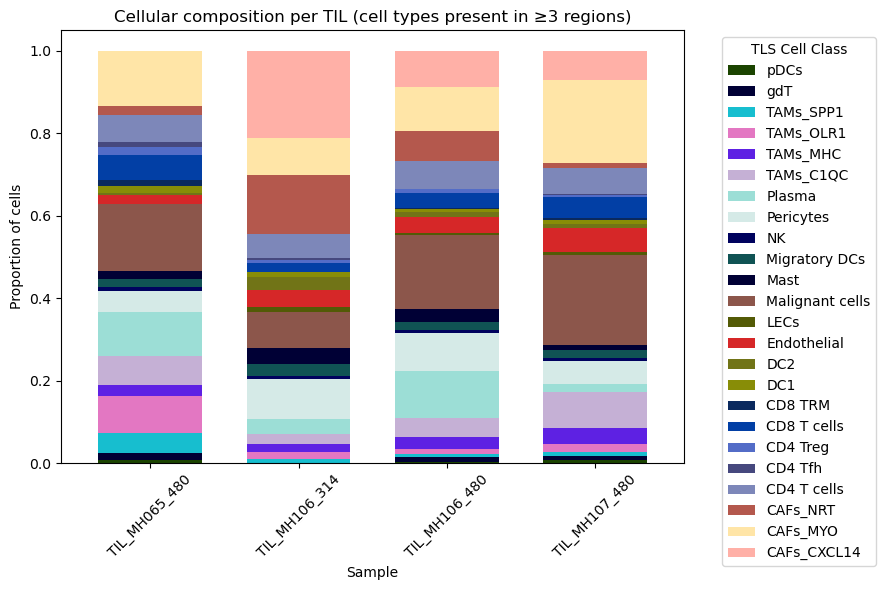

In [6]:
imm_data = {
    "TIL_MH106_314": imm["MH106_314"].obs["TIL_cell_class_threshold"],
    "TIL_MH065_480": imm["MH065_480"].obs["TIL_cell_class_threshold"],
    "TIL_MH107_480": imm["MH107_480"].obs["TIL_cell_class_threshold"],
    "TIL_MH106_480": imm["MH106_480"].obs["TIL_cell_class_threshold"]
}
df_all = pd.concat(
    [pd.DataFrame({"Sample": imm_id, "cell_type": values.astype(str)}) for imm_id, values in imm_data.items()],
    ignore_index=True
)
til_presence = df_all.groupby("cell_type")["Sample"].nunique()
consistent_cell_types = [
    c for c in til_presence[til_presence >= 3].index
    if c not in ['Unclassified', 'Unassigned']
]
df_filtered = df_all[df_all["cell_type"].isin(consistent_cell_types)]

# Count & normalize 
comp = (
    df_filtered.groupby(["Sample", "cell_type"])
    .size()
    .reset_index(name="count")
)

comp["proportion"] = comp.groupby("Sample")["count"].transform(lambda x: x / x.sum())

# Pivot for plotting
pivot = comp.pivot(index="Sample", columns="cell_type", values="proportion").fillna(0)

# order classes
ordered_classes = consistent_cell_types
pivot = pivot[ordered_classes[::-1]]  # reverse for stacking order

#Color map - as above
color_map = {
    'Acinar': '#ffb500',
    'Acinar_REG':'#17becf',
    'Adipocytes': 'black',
    'B cells':  '#ff7f0e',
    'CAFs_CXCL14':'#FFB0A7',
    'CAFs_MYO': '#FFE5A7', #'#c7c7c7',
    'CAFs_NRT': "#B4584D",
    "CD4 T cells":  '#7d87b9',
    "CD4 Tfh" : "#46487E",
    "CD4 Treg": '#536CC7',
    "CD8 T cells":'#023fa5',
    "CD8 TRM": "#0A295E",
    "DC1": "#888D07",
    "DC2": "#717417", 
    "Ductal": '#00846f',
    "Ductal MUC5B":'#8dd593',
    "Endocrine": '#809693',
    "Endothelial":'#d62728',
    "FDCs":"#DD51AD",
    "FRCs": "#00BFA0",
    "LECs": "#535A06",
    "Malignant cells": '#8c564b',
    "Mast": '#000035',
    "Migratory DCs": "#105354",
    "NK": "#00025E",
    "Neutrophils": '#b903aa',
    "Pericytes": '#d5eae7', #'#c5b0d5',
    "Plasma": '#9cded6',
    "SMCs": '#d5eae7', #'#c5b0d5',
    "Schwann": '#b79762',
    "TAMs_C1QC":'#c5b0d5',
    "TAMs_MHC": "#5E21E3",
    "TAMs_OLR1":'#e377c2',
    "TAMs_SPP1": '#17becf',
    "Unclassified": "#cccccc",
    "gdT": '#000035', 
    "pDCs":'#1b4400',
    "Tuft": '#9467bd',
    'Stromal_CCL19': '#D8D18C', 
    "Other": "#cccccc"
}

pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    width=0.7,
    color=[color_map[c] for c in pivot.columns]
)

plt.ylabel("Proportion of cells")
plt.title("Cellular composition per TIL (cell types present in ≥3 regions)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='TLS Cell Class')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "TIL_comp.pdf"))
plt.show()
pivot.to_csv(os.path.join(OUTPUT_DIR, "TIL_composition.tsv"), sep="\t")

## 4. Immune marker dot plot: MH107_480

~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()


~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:748: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


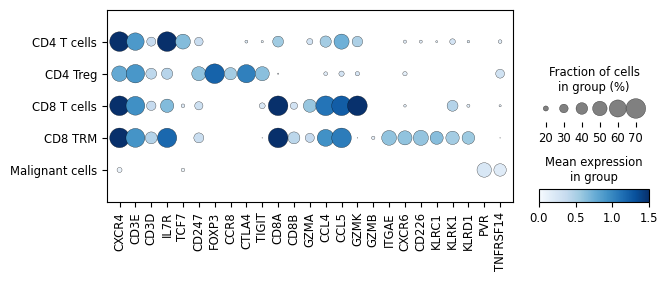

In [7]:
imm_107_480 = imm["MH107_480"]
toplot_107_480 = imm_107_480[imm_107_480.obs['TIL_cell_class_threshold'].isin(['CD4 T cells',
 'CD4 Treg', 'CD8 T cells', 'CD8 TRM','Malignant cells'])]
genes_anno = ['CXCR4','CD3E','CD3D','IL7R','TCF7',#'SELL','LEF1',
              'CD247','FOXP3','CCR8','CTLA4','TIGIT','CD8A','CD8B','GZMA','CCL4','CCL5','GZMK','GZMB','ITGAE','CXCR6','CD226','KLRC1','KLRK1','KLRD1','PVR','TNFRSF14']
sc.pl.dotplot(toplot_107_480, var_names = genes_anno, groupby='TIL_cell_class_threshold', #swap_axes = True, 
             figsize=(7, 2.5), vmax=1.5, vmin = 0,  cmap = 'Blues', dot_max=0.7, dot_min=0.1, save = 'Marker_Immunregulatory.pdf',
             dendrogram=False)

## 5. Distance from malignant cells to the nearest T cell

For each malignant-cell region from `stage3_malignant_TIL.ipynb`, the median distance to the nearest T cell in the TIL region. Original medians: MH106 2,392.3 and 98.7 µm, MH107 1,440.3 and 82.6 µm, MH065 1,552.1 and 53.9 µm, for `noTIL` and `wTIL`.

In [8]:
immune_types = ['CD4 T cells','CD4 Tfh', 'CD4 Treg', 'CD8 T cells', 'CD8 TRM']
rows = []
for sample in ["MH106_480", "MH107_480", "MH065_480"]:
    til = imm[sample]
    til_mask = til.obs['TIL_cell_class_threshold'].isin(immune_types)
    assert til_mask.any(), f"No T cells in the {sample} TIL region"
    til_tree = cKDTree(til.obsm['spatial'][til_mask.values])
    malignant = sc.read_h5ad(os.path.join(MALIGNANT_DIR, f"{sample}_malignant_TIL_regions.h5ad"))
    for region in ["noTIL", "wTIL"]:
        coords = malignant.obsm['spatial'][(malignant.obs["Region"] == region).values]
        distances, _ = til_tree.query(coords, k=1)
        rows.append({"sample": sample, "Region": region, "median_distance_um": np.median(distances)})
distances = pd.DataFrame(rows)
distances.to_csv(os.path.join(OUTPUT_DIR, "malignant_to_TIL_distance.tsv"), sep="\t", index=False)
print(distances)

      sample Region  median_distance_um
0  MH106_480  noTIL         2392.312708
1  MH106_480   wTIL           98.707422
2  MH107_480  noTIL         1440.256091
3  MH107_480   wTIL           82.611637
4  MH065_480  noTIL         1552.104579
5  MH065_480   wTIL           53.878560


## 6. Check against the original region objects

In a passing run, the cells are the same and 100% of them have the same label.

In [9]:
rows = []
for sample, file_name in archived_files.items():
    path = os.path.join(ARCHIVED_DIR, file_name) if ARCHIVED_DIR else None
    if not path or not os.path.exists(path):
        print(f"{sample}: no original region object")
        continue
    reference = sc.read_h5ad(path, backed="r")
    new = imm[sample]
    shared = new.obs_names.intersection(reference.obs_names)
    rows.append({
        "sample": sample,
        "cells": new.n_obs,
        "cells_original": reference.n_obs,
        "shared": len(shared),
        "same_label": f"{(new.obs.loc[shared, 'TIL_cell_class_threshold'].astype(str) == reference.obs.loc[shared, 'cell_class_threshold'].astype(str)).mean():.4%}",
    })
    reference.file.close()
check = pd.DataFrame(rows)
check.to_csv(os.path.join(OUTPUT_DIR, "stage3_TIL_check.tsv"), sep="\t", index=False)
display(check)

,sample,cells,cells_original,shared,same_label
0,MH065_480,10928,10928,10928,100.0000%
1,MH107_480,21695,21695,21695,100.0000%
2,MH106_480,9081,9081,9081,100.0000%
3,MH106_314,39875,39875,39875,100.0000%
